# StratScout — Baseline Pipeline (PyTorch)

**What this notebook is.** A runnable skeleton of the full StratScout pipeline:

```
video frames -> minimap crop -> Model 1 (detector) -> tracker
             -> trajectory tensor -> Model 2 (classifier) -> 5 tactical classes
```

Every stage is implemented with real PyTorch code and real tensors. The stages are
joined by **fixed data contracts** (documented in Section 2) so that five people can
work on five stages in parallel without breaking each other.

**What this notebook is NOT.** It is not trained on CS2. There is no Mirage footage here.
Section 3 generates a *synthetic* toy map that mimics the shape of the problem: coloured
dots moving along routes on a fixed radar. That makes the notebook run end-to-end today,
before you have a single `.dem` file.

> **Read this twice:** every accuracy number this notebook prints is meaningless as a
> research result. The synthetic renderer draws the dots, and the detector then learns to
> find dots that the renderer drew — a closed loop. It proves the *plumbing* works, not
> that the *idea* works. Section 3 is the one module you throw away and replace with real
> captured footage.

**Analogy for the whole notebook:** this is the wiring of a house before the furniture
arrives. Flip every switch, confirm every socket has power, then move the real furniture in.

## 1. Setup and configuration

One config object, no hard-coded paths scattered through the code (README §33.7).
In the real repo this becomes `configs/*.yaml`.

In [21]:
from __future__ import annotations

import json
import math
import random
from dataclasses import dataclass, field, asdict
from pathlib import Path
from typing import Dict, List, Optional, Sequence, Tuple

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)


@dataclass
class Config:
    # --- reproducibility ---
    seed: int = 0

    # --- minimap / frames ---
    minimap_px: int = 128          # side length of the cropped, resized minimap
    crop_box: Tuple[int, int, int, int] = (5, 10, 192, 190)  # (x0, y0, x1, y1) in source video px

    # --- teams / players ---
    n_per_team: int = 5
    teams: Tuple[str, str] = ("T", "CT")

    # --- sequences ---
    seq_len: int = 32              # timesteps per tactical sample
    fps_sampled: float = 4.0       # frames per second after sampling -> 32 steps = 8 s

    # --- dataset sizes (synthetic; replace with real counts later) ---
    n_matches_train: int = 1 # Original: 12
    n_matches_val: int = 1 # Original: 3
    n_matches_test: int = 1 # Original: 3
    rounds_per_match: int = 2 # Original: 20

    # --- detector ---
    det_stride: int = 1            # heatmap side = minimap_px // det_stride (1 = full res)
    det_sigma: float = 1.0         # gaussian radius of the heatmap target, in heatmap px
    det_frames_train: int = 400
    det_frames_val: int = 120
    det_epochs: int = 10
    det_lr: float = 2e-3
    det_batch: int = 32
    det_peak_thresh: float = 0.20
    det_match_radius: float = 0.035  # normalised distance counted as a correct detection

    # --- tracker ---
    track_gate: float = 0.09       # max normalised movement between frames to link
    track_max_miss: int = 8        # frames a track may go unseen before it is dropped

    # --- classifier ---
    cls_epochs: int = 40
    cls_lr: float = 2e-3
    cls_batch: int = 32
    cls_hidden: int = 96

    # --- paths ---
    out_dir: str = "runs/baseline"


CFG = Config()
CLASSES = ["A_DEFAULT", "B_DEFAULT", "A_SPLIT", "B_SPLIT", "RETAKE"]
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
N_CLASSES = len(CLASSES)


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(CFG.seed)
Path(CFG.out_dir).mkdir(parents=True, exist_ok=True)
print(json.dumps(asdict(CFG), indent=2)[:400] + " ...")

device: cpu
{
  "seed": 0,
  "minimap_px": 128,
  "crop_box": [
    5,
    10,
    192,
    190
  ],
  "n_per_team": 5,
  "teams": [
    "T",
    "CT"
  ],
  "seq_len": 32,
  "fps_sampled": 4.0,
  "n_matches_train": 1,
  "n_matches_val": 1,
  "n_matches_test": 1,
  "rounds_per_match": 2,
  "det_stride": 1,
  "det_sigma": 1.0,
  "det_frames_train": 400,
  "det_frames_val": 120,
  "det_epochs": 10,
  "det_lr":  ...


## 2. Data contracts between stages

This is the most important cell in the notebook and contains no maths.

With five people building five stages, the thing that kills the project is not a bad model
— it is Member 3 returning a list of tuples when Member 4 expected a tensor. So we fix the
shapes **now**, in writing, and every stage promises to honour them.

Think of it like plug sockets: as long as everyone agrees on the plug shape, you can swap
the appliance without rewiring the house.

| Stage | Output name | Type / shape | Meaning |
|---|---|---|---|
| Pre-processing | `frames` | `float32 (N, 3, H, W)`, values 0–1 | cropped, resized, normalised minimap |
| Detector | `detections` | list of length `N`; each `{"T": (k,3), "CT": (m,3)}` | rows are `(x, y, score)`, `x,y` normalised to `[0,1]` |
| Tracker | `positions` | `float32 (N, 10, 2)` | players 0–4 = T, 5–9 = CT, gaps filled |
| Trajectory | `sequence` | `float32 (T, D)` | model-ready tensor, `D` depends on representation |
| Classifier | `logits` | `float32 (B, 5)` | order fixed by `CLASSES` |

**Coordinate convention:** `x` to the right, `y` downward (image convention), both in
`[0, 1]` relative to the minimap crop. Never pass raw pixels across a stage boundary —
pixels change when someone changes the resolution, normalised coordinates do not.

**Player identity:** we deliberately do *not* promise that index 2 is the same human across
frames. The icons are identical dots; identity is unrecoverable from pixels alone when two
players cross. README §14 already accepts this. Section 7 explains how we work around it.

In [22]:
TEAM_IDX = {"T": 0, "CT": 1}
N_PLAYERS = CFG.n_per_team * 2


def empty_detections(n_frames: int) -> List[Dict[str, np.ndarray]]:
    """Canonical empty structure, useful as a stub while a stage is unfinished."""
    return [{t: np.zeros((0, 3), dtype=np.float32) for t in CFG.teams} for _ in range(n_frames)]


def check_contract(name: str, arr: torch.Tensor | np.ndarray, expected: Tuple) -> None:
    """Cheap runtime assertion so a broken stage fails loudly instead of silently."""
    got = tuple(arr.shape)
    ok = len(got) == len(expected) and all(e is None or e == g for e, g in zip(expected, got))
    if not ok:
        raise ValueError(f"[contract] {name}: expected {expected}, got {got}")


print("contracts defined")

contracts defined


## 3. Synthetic data generator — **the throwaway module**

Replace this entire section with real data once you can capture Mirage footage.

It fakes a tiny map with a T spawn at the bottom, an A site top-right, a B site top-left,
and mid in the middle. For each round it walks 5 attacker dots along class-appropriate
routes and 5 defender dots around anchors, then renders them onto a fixed background.

It produces exactly the two things a real capture pipeline must produce:

1. **`positions`** — the exact coordinates, standing in for parsed `.dem` output.
2. **`frames`** — the rendered minimap video, standing in for captured footage.

Note it also assigns a `match_id`. That is not decoration: Section 5 splits by match, never
by frame, because frames from one round are near-duplicates of each other (README §19).

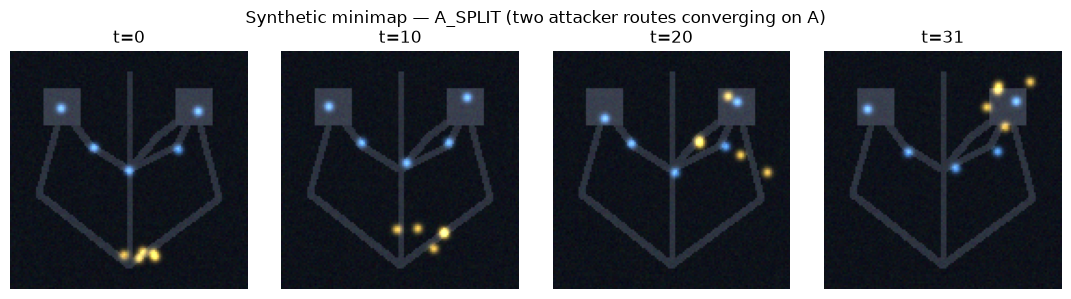

In [23]:
MAP_POINTS = {
    "t_spawn":   (0.50, 0.90),
    "ct_spawn":  (0.50, 0.10),
    "a_site":    (0.78, 0.24),
    "b_site":    (0.22, 0.24),
    "mid":       (0.50, 0.50),
    "a_ramp":    (0.88, 0.62),
    "a_palace":  (0.70, 0.40),
    "connector": (0.62, 0.36),
    "b_apps":    (0.12, 0.60),
    "b_short":   (0.34, 0.40),
}
A_SITE = np.array(MAP_POINTS["a_site"], dtype=np.float32)
B_SITE = np.array(MAP_POINTS["b_site"], dtype=np.float32)


def _polyline(waypoints: np.ndarray, s: np.ndarray) -> np.ndarray:
    """Sample a polyline at arc-length fractions `s` in [0, 1]. Returns (len(s), 2)."""
    wp = np.asarray(waypoints, dtype=np.float64)
    seg = np.linalg.norm(np.diff(wp, axis=0), axis=1)
    cum = np.concatenate([[0.0], np.cumsum(seg)])
    total = max(cum[-1], 1e-9)
    d = np.clip(s, 0.0, 1.0) * total
    i = np.clip(np.searchsorted(cum, d, side="right") - 1, 0, len(seg) - 1)
    frac = (d - cum[i]) / np.maximum(seg[i], 1e-9)
    return wp[i] + (wp[i + 1] - wp[i]) * frac[:, None]


def _jitter_waypoints(names: Sequence[str], rng: np.random.Generator,
                      amt: float = 0.02, end_amt: float = 0.06) -> np.ndarray:
    """Perturb a named route.

    Endpoints get a *larger* offset than interior waypoints on purpose: five players do not
    stand on one pixel at spawn, and they fan out when they arrive on a site. Without this,
    five icons overlap into a single blob and no detector on earth can separate them.
    """
    wp = np.array([MAP_POINTS[n] for n in names], dtype=np.float64)
    if len(wp) > 2:
        wp[1:-1] += rng.normal(0, amt, wp[1:-1].shape)
    wp[0] += rng.normal(0, end_amt, 2)
    wp[-1] += rng.normal(0, end_amt, 2)
    return np.clip(wp, 0.04, 0.96)


def _walk(names: Sequence[str], n: int, rng: np.random.Generator,
          delay: float = 0.0, duration: float = 1.0, jitter: float = 0.008) -> np.ndarray:
    """One player's path along a named route, as (n, 2) normalised coordinates."""
    wp = _jitter_waypoints(names, rng)
    tt = np.linspace(0.0, 1.0, n)
    s = np.clip((tt - delay) / max(duration, 1e-6), 0.0, 1.0)
    s = s * s * (3 - 2 * s)                      # ease in/out: players accelerate then settle
    pts = _polyline(wp, s) + rng.normal(0, jitter, (n, 2))
    return np.clip(pts, 0.03, 0.97)


def _hold(anchor: Sequence[float], n: int, rng: np.random.Generator, amp: float = 0.012) -> np.ndarray:
    """A defender loitering near a position: slow random drift, not a straight line."""
    drift = np.cumsum(rng.normal(0, amp, (n, 2)), axis=0) * 0.5
    pts = np.array(anchor, dtype=np.float64)[None, :] + drift + rng.normal(0, 0.006, (n, 2))
    return np.clip(pts, 0.03, 0.97)


T_ROUTES = {
    "A_DEFAULT": [["t_spawn", "a_ramp", "a_site"]] * 5,
    "B_DEFAULT": [["t_spawn", "b_apps", "b_site"]] * 5,
    "A_SPLIT":   [["t_spawn", "a_ramp", "a_site"]] * 3 +
                 [["t_spawn", "mid", "connector", "a_site"]] * 2,
    "B_SPLIT":   [["t_spawn", "b_apps", "b_site"]] * 3 +
                 [["t_spawn", "mid", "b_short", "b_site"]] * 2,
}
CT_ANCHORS = ["a_site", "a_palace", "mid", "b_short", "b_site"]


def make_round(label: str, rng: np.random.Generator, n: int) -> np.ndarray:
    """Return exact positions (n, 10, 2). Index 0-4 = T, 5-9 = CT."""
    pos = np.zeros((n, N_PLAYERS, 2), dtype=np.float32)

    if label == "RETAKE":
        # Attackers already hold a site; defenders converge back onto it.
        site = "a_site" if rng.random() < 0.5 else "b_site"
        anchor = np.array(MAP_POINTS[site])
        for p in range(5):
            off = rng.normal(0, 0.035, 2)
            pos[:, p] = _hold(np.clip(anchor + off, 0.05, 0.95), n, rng, amp=0.008)
        rotate_from = ["ct_spawn", "mid", "connector", "b_short", "a_palace"]
        for p in range(5):
            route = [rotate_from[p], "ct_spawn", site] if rng.random() < 0.4 else [rotate_from[p], site]
            pos[:, 5 + p] = _walk(route, n, rng,
                                  delay=rng.uniform(0.05, 0.30),
                                  duration=rng.uniform(0.45, 0.75))
    else:
        for p, route in enumerate(T_ROUTES[label]):
            pos[:, p] = _walk(route, n, rng,
                              delay=rng.uniform(0.0, 0.25),
                              duration=rng.uniform(0.55, 0.9))
        for p, a in enumerate(CT_ANCHORS):
            pos[:, 5 + p] = _hold(MAP_POINTS[a], n, rng)

    return pos


def build_background(size: int, rng: np.random.Generator) -> np.ndarray:
    """A static fake radar image: corridors and sites, identical in every frame."""
    bg = np.full((size, size, 3), (14, 18, 26), dtype=np.float32)
    corridors = [
        ["t_spawn", "a_ramp", "a_site"], ["t_spawn", "b_apps", "b_site"],
        ["t_spawn", "mid", "ct_spawn"], ["mid", "connector", "a_site"],
        ["mid", "b_short", "b_site"], ["a_site", "a_palace", "mid"],
    ]
    s = np.linspace(0, 1, 400)
    for names in corridors:
        pts = _polyline(np.array([MAP_POINTS[n] for n in names]), s) * size
        for dx in (-1, 0, 1):
            for dy in (-1, 0, 1):
                xs = np.clip(pts[:, 0].astype(int) + dx, 0, size - 1)
                ys = np.clip(pts[:, 1].astype(int) + dy, 0, size - 1)
                bg[ys, xs] = (46, 52, 64)
    for name in ("a_site", "b_site"):
        cx, cy = (np.array(MAP_POINTS[name]) * size).astype(int)
        r = size // 12
        bg[max(cy - r, 0):cy + r, max(cx - r, 0):cx + r] = (58, 64, 78)
    bg += rng.normal(0, 3.0, bg.shape)
    return np.clip(bg, 0, 255)


_GRID_CACHE: Dict[int, Tuple[np.ndarray, np.ndarray]] = {}


def _grid(size: int) -> Tuple[np.ndarray, np.ndarray]:
    if size not in _GRID_CACHE:
        yy, xx = np.meshgrid(np.arange(size), np.arange(size), indexing="ij")
        _GRID_CACHE[size] = (xx.astype(np.float32), yy.astype(np.float32))
    return _GRID_CACHE[size]


T_COLOUR = np.array([250, 200, 70], dtype=np.float32)
CT_COLOUR = np.array([90, 165, 255], dtype=np.float32)


def render_frames(pos: np.ndarray, bg: np.ndarray, size: int,
                  rng: np.random.Generator, radius: float = 1.7) -> np.ndarray:
    """positions (n, 10, 2) -> uint8 video (n, size, size, 3)."""
    xx, yy = _grid(size)
    n = pos.shape[0]
    out = np.empty((n, size, size, 3), dtype=np.uint8)
    colours = np.stack([T_COLOUR] * CFG.n_per_team + [CT_COLOUR] * CFG.n_per_team)  # (10,3)
    for f in range(n):
        px = pos[f, :, 0] * size
        py = pos[f, :, 1] * size
        d2 = (xx[None] - px[:, None, None]) ** 2 + (yy[None] - py[:, None, None]) ** 2
        blob = np.exp(-d2 / (2 * radius ** 2))                       # (10, size, size)
        img = bg + np.einsum("psq,pc->sqc", blob, colours)
        img += rng.normal(0, 3.0, img.shape)
        out[f] = np.clip(img, 0, 255).astype(np.uint8)
    return out


# quick visual sanity check
_rng = np.random.default_rng(CFG.seed)
_bg = build_background(CFG.minimap_px, _rng)
_demo_pos = make_round("A_SPLIT", _rng, CFG.seq_len)
_demo_frames = render_frames(_demo_pos, _bg, CFG.minimap_px, _rng)

fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for ax, f in zip(axes, [0, 10, 20, 31]):
    ax.imshow(_demo_frames[f]); ax.set_title(f"t={f}"); ax.axis("off")
fig.suptitle("Synthetic minimap — A_SPLIT (two attacker routes converging on A)")
plt.tight_layout(); plt.show()

## 4. Building the dataset

`Round` bundles everything one labelled sample needs. It mirrors the JSON schema in
README §9, so swapping synthetic rounds for real annotated rounds is a change of *producer*,
not a change of *format*.

In [24]:
@dataclass
class Round:
    match_id: str
    round_idx: int
    label: str
    positions: np.ndarray                   # (T, 10, 2) exact -> stands in for .dem
    frames: Optional[np.ndarray] = None     # (T, H, W, 3) uint8 -> stands in for footage

    @property
    def y(self) -> int:
        return CLASS_TO_IDX[self.label]


def generate_split(n_matches: int, prefix: str, seed: int, render: bool) -> List[Round]:
    rng = np.random.default_rng(seed)
    bg = build_background(CFG.minimap_px, np.random.default_rng(1234))  # background fixed across splits
    rounds: List[Round] = []
    for m in range(n_matches):
        match_id = f"{prefix}_match_{m:03d}"
        # a real team has tendencies -> class frequencies differ per match
        weights = rng.dirichlet(np.ones(N_CLASSES) * 2.5)
        for r in range(CFG.rounds_per_match):
            label = CLASSES[int(rng.choice(N_CLASSES, p=weights))]
            pos = make_round(label, rng, CFG.seq_len)
            frames = render_frames(pos, bg, CFG.minimap_px, rng) if render else None
            rounds.append(Round(match_id, r, label, pos, frames))
    return rounds


# Frames are only rendered where the vision path actually needs them, to save memory.
train_rounds = generate_split(CFG.n_matches_train, "train", CFG.seed + 1, render=False)
val_rounds   = generate_split(CFG.n_matches_val,   "val",   CFG.seed + 2, render=False)
test_rounds  = generate_split(CFG.n_matches_test,  "test",  CFG.seed + 3, render=True)

# a small pool of rendered rounds to train/validate the detector on
det_pool      = generate_split(3, "detpool",     CFG.seed + 4, render=True)
det_pool_val  = generate_split(1, "detpoolval",  CFG.seed + 5, render=True)

print(f"train {len(train_rounds)} | val {len(val_rounds)} | test {len(test_rounds)} rounds")
counts = {c: sum(r.label == c for r in train_rounds) for c in CLASSES}
print("train class counts:", counts)

train 2 | val 2 | test 2 rounds
train class counts: {'A_DEFAULT': 0, 'B_DEFAULT': 0, 'A_SPLIT': 1, 'B_SPLIT': 1, 'RETAKE': 0}


### 4.1 Splitting by match, not by frame

Frames inside one round are almost the same picture. If you shuffle frames and split
randomly, the test set is full of near-copies of training frames and your accuracy is a
lie — like revising with the exam paper. We generated the splits from disjoint match ids,
so let's prove no id leaks across them.

In [25]:
ids = {n: {r.match_id for r in rs} for n, rs in
       [("train", train_rounds), ("val", val_rounds), ("test", test_rounds)]}
assert not (ids["train"] & ids["val"]), "leakage: train/val share a match"
assert not (ids["train"] & ids["test"]), "leakage: train/test share a match"
assert not (ids["val"] & ids["test"]), "leakage: val/test share a match"
print("no match-id overlap between splits ✓")

no match-id overlap between splits ✓


## 5. Stage 1 — minimap pre-processing

Crop the radar out of the frame, resize to a fixed size, scale to 0–1, and move the colour
channel to the front (PyTorch wants `(batch, channels, height, width)`, images arrive as
`(height, width, channels)`).

Why a *fixed* crop matters: if the crop box wobbles, the same map location lands on
different pixels and the detector has to learn a moving target. This is the code-level
version of README §11.

In [26]:
class MinimapPreprocessor(nn.Module):
    def __init__(self, crop_box: Tuple[int, int, int, int], out_px: int):
        super().__init__()
        self.crop_box = crop_box
        self.out_px = out_px

    def forward(self, frames_hwc: np.ndarray | torch.Tensor) -> torch.Tensor:
        """(N, H, W, 3) uint8  ->  (N, 3, out_px, out_px) float32 in [0,1]."""
        x = torch.as_tensor(np.ascontiguousarray(frames_hwc))
        if x.ndim == 3:
            x = x[None]
        x = x.permute(0, 3, 1, 2).float() / 255.0
        x0, y0, x1, y1 = self.crop_box
        x = x[:, :, y0:y1, x0:x1]
        if x.shape[-1] != self.out_px or x.shape[-2] != self.out_px:
            x = F.interpolate(x, size=(self.out_px, self.out_px), mode="bilinear", align_corners=False)
        return x


PRE = MinimapPreprocessor(CFG.crop_box, CFG.minimap_px)
_t = PRE(test_rounds[0].frames)
check_contract("frames", _t, (CFG.seq_len, 3, CFG.minimap_px, CFG.minimap_px))
print("preprocessed:", tuple(_t.shape), _t.dtype, f"range [{_t.min():.2f}, {_t.max():.2f}]")

preprocessed: (32, 3, 128, 128) torch.float32 range [0.00, 1.00]


## 6. Stage 2 — Model 1: the player-icon detector

Your flowchart says "CNN-based player-icon detector → boxes". For minimap icons I'd skip
boxes entirely and predict **centre heatmaps** instead, which is simpler and more accurate
here. Reasons:

* every icon is the same size, so a box adds no information a centre doesn't already give;
* you need a *point* downstream anyway (the tracker consumes coordinates, not boxes);
* bounding-box labelling of dots is slow and noisy; a click on the centre is not.

**How a heatmap detector works.** The network outputs a small greyscale image per team —
think of a weather map where "rain" means "a player icon is here". Bright blob at (x, y)
= a player at (x, y). Training pushes a soft Gaussian bump onto the true location; at
inference we just look for the local peaks.

Two channels: channel 0 = T, channel 1 = CT. Team classification therefore comes free from
*which* heatmap the peak appears in.

In [27]:
class MinimapDetector(nn.Module):
    """Small encoder-decoder producing one centre-heatmap per team."""

    def __init__(self, n_classes: int = 2, width: int = 32, out_stride: int = CFG.det_stride):
        super().__init__()
        w = width
        self.out_stride = out_stride
        self.enc = nn.Sequential(
            nn.Conv2d(3, w, 3, stride=2, padding=1), nn.BatchNorm2d(w), nn.ReLU(inplace=True),
            nn.Conv2d(w, w, 3, padding=1),           nn.BatchNorm2d(w), nn.ReLU(inplace=True),
            nn.Conv2d(w, w * 2, 3, stride=2, padding=1), nn.BatchNorm2d(w * 2), nn.ReLU(inplace=True),
            nn.Conv2d(w * 2, w * 2, 3, padding=1),   nn.BatchNorm2d(w * 2), nn.ReLU(inplace=True),
        )
        dec = [nn.Upsample(scale_factor=2, mode="nearest"),
               nn.Conv2d(w * 2, w, 3, padding=1), nn.BatchNorm2d(w), nn.ReLU(inplace=True),
               nn.Conv2d(w, w, 3, padding=1),     nn.BatchNorm2d(w), nn.ReLU(inplace=True)]
        head_ch = w
        if out_stride == 1:
            # Full-resolution output. Costs more compute, but the 3x3 peak suppression in
            # decode_heatmap works in *heatmap* pixels: at stride 2, two players 4 px apart in
            # the image are only 2 heatmap px apart and one of them gets suppressed as a
            # duplicate. Full resolution doubles the separation the decoder can see.
            dec += [nn.Upsample(scale_factor=2, mode="nearest"),
                    nn.Conv2d(w, w // 2, 3, padding=1), nn.BatchNorm2d(w // 2), nn.ReLU(inplace=True)]
            head_ch = w // 2
        self.dec = nn.Sequential(*dec)
        self.head = nn.Conv2d(head_ch, n_classes, 1)
        self.head.bias.data.fill_(-2.19)  # start pessimistic: most pixels are background

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """(B,3,H,W) -> (B,2,H/stride,W/stride) raw logits."""
        return self.head(self.dec(self.enc(x)))


def gaussian_heatmap(pos: np.ndarray, out_px: int, sigma: float) -> torch.Tensor:
    """positions (10,2) normalised -> (2, out_px, out_px) target heatmap."""
    xx, yy = _grid(out_px)
    hm = np.zeros((2, out_px, out_px), dtype=np.float32)
    for p in range(N_PLAYERS):
        ch = 0 if p < CFG.n_per_team else 1
        ix = int(np.clip(round(pos[p, 0] * out_px), 0, out_px - 1))
        iy = int(np.clip(round(pos[p, 1] * out_px), 0, out_px - 1))
        # Centre the gaussian on the *integer* pixel and force that pixel to exactly 1.0.
        # If you centre on the sub-pixel location instead, the brightest pixel may only reach
        # ~0.8, the focal loss finds no positive pixels at all, and the detector silently
        # learns to predict nothing. That failure looks like a broken model; it is a broken
        # label. Cost: up to half a pixel of quantisation error, which is negligible here.
        g = np.exp(-((xx - ix) ** 2 + (yy - iy) ** 2) / (2 * sigma ** 2))
        hm[ch] = np.maximum(hm[ch], g)
        hm[ch, iy, ix] = 1.0
    return torch.from_numpy(hm)

def gaussian_heatmap_single(pos, out_px, sigma):
    xx, yy = _grid(out_px)
    hm = np.zeros((1, out_px, out_px), np.float32)
    for p in pos:
        if not np.isfinite(p).all() or p[0] < 0:
            continue
        ix = int(np.clip(round(float(p[0]) * out_px), 0, out_px - 1))
        iy = int(np.clip(round(float(p[1]) * out_px), 0, out_px - 1))
        g = np.exp(-((xx - ix) ** 2 + (yy - iy) ** 2) / (2 * sigma ** 2))
        hm[0] = np.maximum(hm[0], g)
        hm[0, iy, ix] = 1.0
    return torch.from_numpy(hm)

def focal_heatmap_loss(logits: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
    """CenterNet-style penalty-reduced focal loss.

    Plain cross-entropy would drown: ~99.5% of pixels are background, so the network could
    predict 'nothing anywhere' and score well. This loss down-weights easy background pixels
    and pixels near a true centre (a near-miss is not as wrong as a far-miss).
    """
    p = torch.sigmoid(logits).clamp(1e-4, 1 - 1e-4)
    pos_mask = target.ge(0.999).float()
    neg_mask = 1.0 - pos_mask
    pos_loss = -((1 - p) ** 2) * torch.log(p) * pos_mask
    neg_loss = -((1 - target) ** 4) * (p ** 2) * torch.log(1 - p) * neg_mask
    n_pos = pos_mask.sum().clamp(min=1.0)
    return (pos_loss.sum() + neg_loss.sum()) / n_pos


print(MinimapDetector())

MinimapDetector(
  (enc): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (11): ReLU(inplace=True)
  )
  (dec): Sequential(
    (0): Upsample(scale_factor=2.0, mode='nearest')
    (1): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1

### 6.1 Detector dataset

One training example = one frame + its heatmap target. In the real project the target comes
from **hand-labelled icon centres** (or from `.dem` coordinates projected onto the minimap,
once you have verified that projection is exact). That is the missing yellow arrow I
flagged on your flowchart.

In [28]:
from setup_capture_tools import load_labels

f_all, p_all = load_labels(np.load('pilot_frames.npy'), 'pilot_labels.json', max_icons=5)
print("labelled frames:", len(f_all))

class RealFrames(Dataset):
    def __init__(self, frames, positions):
        self.frames, self.positions = frames, positions
        self.out_px = CFG.minimap_px // CFG.det_stride
    def __len__(self): return len(self.frames)
    def __getitem__(self, i):
        x = PRE(self.frames[i])[0]
        y = gaussian_heatmap_single(self.positions[i], self.out_px, CFG.det_sigma)
        return x, y, torch.from_numpy(np.nan_to_num(self.positions[i], nan=-1.0))

cut = int(len(f_all) * 0.8)
det_train, det_val = RealFrames(f_all[:cut], p_all[:cut]), RealFrames(f_all[cut:], p_all[cut:])
det_train_dl = DataLoader(det_train, batch_size=CFG.det_batch, shuffle=True, drop_last=True)
det_val_dl = DataLoader(det_val, batch_size=CFG.det_batch)
print(f"train={len(det_train)} val={len(det_val)}")

labelled frames: 386
train=308 val=78


### 6.2 Decoding a heatmap back into coordinates

The 3×3 max-pool trick is a cheap non-maximum suppression: keep a pixel only if it is the
brightest in its neighbourhood. Without it, one player produces a cluster of adjacent
"detections" — like a single voice echoing and being counted as a crowd.

In [29]:
@torch.no_grad()
def decode_heatmap(logits: torch.Tensor, thresh: float, max_per_team: int) -> List[Dict[str, np.ndarray]]:
    """(B,2,h,w) logits -> list of B dicts {'T': (k,3), 'CT': (m,3)} with (x, y, score)."""
    prob = torch.sigmoid(logits)
    peaks = (F.max_pool2d(prob, 3, stride=1, padding=1) == prob).float()
    prob = prob * peaks
    B, C, h, w = prob.shape
    flat = prob.view(B, C, -1)
    scores, idx = flat.topk(max_per_team, dim=-1)
    ys = (idx // w).float() / h
    xs = (idx % w).float() / w
    out: List[Dict[str, np.ndarray]] = []
    for b in range(B):
        d: Dict[str, np.ndarray] = {}
        for c, team in enumerate(CFG.teams[:prob.shape[1]]):
            keep = scores[b, c] >= thresh
            d[team] = torch.stack([xs[b, c][keep], ys[b, c][keep], scores[b, c][keep]], -1).cpu().numpy()
        out.append(d)
    return out


@torch.no_grad()
def detector_metrics(model: nn.Module, loader: DataLoader) -> Dict[str, float]:
    """Precision / recall / F1 at a distance threshold, plus mean positional error."""
    model.eval()
    tp = fp = fn = 0
    errs: List[float] = []
    for x, _, pos in loader:
        dets = decode_heatmap(model(x.to(DEVICE)), CFG.det_peak_thresh, CFG.n_per_team)
        for b in range(x.shape[0]):
            for c, team in enumerate(CFG.teams[:1]):    
                g = pos[b].numpy()
                gt = g[np.isfinite(g[:, 0]) & (g[:, 0] >= 0)]
                pred = dets[b][team]
                if len(gt) == 0:
                    fp += len(pred)
                    continue
                used = set()
                order = np.argsort(-pred[:, 2]) if len(pred) else []
                for pi in order:
                    d = np.linalg.norm(gt - pred[pi, :2], axis=1)
                    d[list(used)] = np.inf
                    j = int(np.argmin(d))
                    if d[j] <= CFG.det_match_radius:
                        tp += 1; used.add(j); errs.append(float(d[j]))
                    else:
                        fp += 1
                fn += len(gt) - len(used)
    prec = tp / max(tp + fp, 1)
    rec = tp / max(tp + fn, 1)
    return {"precision": prec, "recall": rec,
            "f1": 2 * prec * rec / max(prec + rec, 1e-9),
            "mean_pos_err_norm": float(np.mean(errs)) if errs else float("nan")}

### 6.3 Train the detector

In [30]:
def train_detector(cfg: Config = CFG) -> MinimapDetector:
    set_seed(cfg.seed)
    model = MinimapDetector(n_classes=1).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.det_lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg.det_epochs)
    for ep in range(cfg.det_epochs):
        model.train()
        tot = 0.0
        for x, y, _ in det_train_dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = focal_heatmap_loss(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * x.shape[0]
        sched.step()
        m = detector_metrics(model, det_val_dl)
        print(f"epoch {ep+1:2d}/{cfg.det_epochs}  loss {tot/len(det_train):.4f}  "
              f"val P {m['precision']:.3f} R {m['recall']:.3f} F1 {m['f1']:.3f}  "
              f"err {m['mean_pos_err_norm']*cfg.minimap_px:.2f}px")
    return model


detector = train_detector()
DET_METRICS = detector_metrics(detector, det_val_dl)
print("\nfinal detector:", {k: round(v, 4) for k, v in DET_METRICS.items()})
torch.save(detector.state_dict(), Path(CFG.out_dir) / "detector.pt")

epoch  1/10  loss 14.3819  val P 0.000 R 0.000 F1 0.000  err nanpx
epoch  2/10  loss 7.1378  val P 0.000 R 0.000 F1 0.000  err nanpx
epoch  3/10  loss 5.6935  val P 0.000 R 0.000 F1 0.000  err nanpx
epoch  4/10  loss 4.9251  val P 0.000 R 0.000 F1 0.000  err nanpx
epoch  5/10  loss 4.4242  val P 0.000 R 0.000 F1 0.000  err nanpx
epoch  6/10  loss 4.0936  val P 0.000 R 0.000 F1 0.000  err nanpx
epoch  7/10  loss 3.8746  val P 0.600 R 0.043 F1 0.080  err 1.70px
epoch  8/10  loss 3.7774  val P 0.711 R 0.280 F1 0.401  err 2.00px
epoch  9/10  loss 3.7000  val P 0.631 R 0.389 F1 0.481  err 1.85px
epoch 10/10  loss 3.7005  val P 0.617 R 0.512 F1 0.560  err 1.94px

final detector: {'precision': 0.6171, 'recall': 0.5118, 'f1': 0.5596, 'mean_pos_err_norm': 0.0151}


(386, 180, 187, 3) uint8


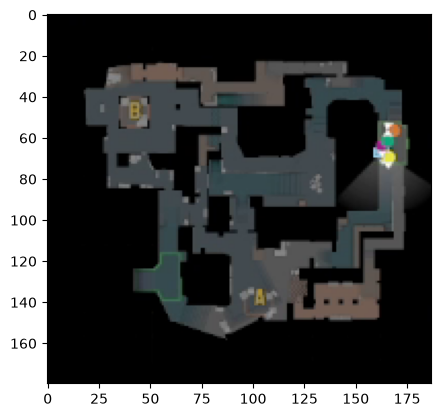

In [ ]:
## Quick visual sanity check of the trained detector
print(f_all.shape, f_all.dtype)
import matplotlib.pyplot as plt
plt.imshow(f_all[0]); plt.show()

## 7. Stage 3 — tracking

The detector answers "where are the dots in *this* frame". The tracker answers "which dot
in this frame is the same dot as in the previous frame".

Baseline method: **greedy nearest neighbour with a gate.** For each existing track, look for
the closest new detection within `track_gate` (a player cannot teleport across the map in a
quarter of a second). If found, extend the track; if not, mark it missing. Unclaimed
detections start new tracks.

We track each team separately, which halves the problem for free — a T dot can never be
confused with a CT dot because they come out of different heatmap channels.

**This baseline is not good enough, and the notebook proves it.** README §14 says "start
with the simplest approach that performs reliably" — the important half of that sentence is
*reliably*. Section 7.1 measures both this tracker and a fixed-slot replacement against
exact positions, and the gap is large. Keep both: having a measured baseline to beat is
worth more than quietly deleting the version that lost.

**Known limitation we do accept:** when two teammates cross paths their identities can swap.
Real trackers fix this with appearance features, but identical icons have no appearance to
use. That is fine here because the classifier reads *team shape*, not individual identity —
Section 8 makes that assumption explicit.

In [20]:
@dataclass
class Track:
    positions: Dict[int, np.ndarray] = field(default_factory=dict)  # frame index -> (x, y)
    last_seen: int = -1
    last_pos: np.ndarray = field(default_factory=lambda: np.zeros(2, np.float32))


def track_team(dets_per_frame: List[np.ndarray], gate: float, max_miss: int) -> List[Track]:
    tracks: List[Track] = []
    for f, det in enumerate(dets_per_frame):
        alive = [t for t in tracks if f - t.last_seen <= max_miss]
        claimed: set = set()
        # cost-sorted greedy assignment: cheapest pairs win first
        pairs = []
        for ti, t in enumerate(alive):
            for di in range(len(det)):
                d = float(np.linalg.norm(det[di, :2] - t.last_pos))
                if d <= gate:
                    pairs.append((d, ti, di))
        pairs.sort()
        matched_t, matched_d = set(), set()
        for d, ti, di in pairs:
            if ti in matched_t or di in matched_d:
                continue
            t = alive[ti]
            t.positions[f] = det[di, :2].astype(np.float32)
            t.last_pos = det[di, :2].astype(np.float32)
            t.last_seen = f
            matched_t.add(ti); matched_d.add(di); claimed.add(di)
        for di in range(len(det)):
            if di not in claimed:
                t = Track()
                t.positions[f] = det[di, :2].astype(np.float32)
                t.last_pos = det[di, :2].astype(np.float32)
                t.last_seen = f
                tracks.append(t)
    return tracks


def tracks_to_positions(tracks: List[Track], n_frames: int, n_slots: int) -> np.ndarray:
    """Pick the `n_slots` longest tracks and densify them into (n_frames, n_slots, 2).

    Gaps are filled by carrying the last known position forward (and the first known
    position backward) — a dot that briefly disappears is assumed to have stayed put.
    """
    tracks = sorted(tracks, key=lambda t: -len(t.positions))[:n_slots]
    out = np.zeros((n_frames, n_slots, 2), dtype=np.float32)
    for s in range(n_slots):
        if s < len(tracks) and tracks[s].positions:
            frames = sorted(tracks[s].positions)
            arr = np.full((n_frames, 2), np.nan, dtype=np.float32)
            for f in frames:
                arr[f] = tracks[s].positions[f]
            idx = np.where(~np.isnan(arr[:, 0]))[0]
            first, last = idx[0], idx[-1]
            arr[:first] = arr[first]
            arr[last + 1:] = arr[last]
            for f in range(first, last + 1):           # forward-fill interior gaps
                if np.isnan(arr[f, 0]):
                    arr[f] = arr[f - 1]
            out[:, s] = arr
        else:
            out[:, s] = 0.5                            # missing player -> map centre
    # canonical slot order: sort by mean x so slot 0 is always the left-most player
    order = np.argsort(out.mean(axis=0)[:, 0])
    return out[:, order]


class FixedSlotTracker:
    """Maintains exactly `n_slots` persistent slots per team.

    The free-track tracker above is the textbook baseline, and on this data it fails: because
    the detector misses ~7% of icons, every dropped frame orphans a track and every recovery
    spawns a fresh one, so five players turn into ~20 fragments and "keep the longest five"
    grabs fragments instead of players.

    This tracker uses a fact the free tracker throws away: **there are exactly five players
    per team**. Slots are created once and never destroyed. A slot that loses its detection
    coasts along its last known velocity instead of dying, and a spare detection is handed
    back to whichever slot has been lost longest rather than starting a new track.

    Analogy: the free tracker is a register that adds a new pupil every time someone returns
    from the toilet. This one keeps five named seats and marks people temporarily absent.
    """

    def __init__(self, n_slots: int, gate: float, max_miss: int, smooth: float = 0.6):
        self.n_slots, self.gate, self.max_miss, self.smooth = n_slots, gate, max_miss, smooth

    def run(self, dets_per_frame: List[np.ndarray]) -> np.ndarray:
        n = len(dets_per_frame)
        out = np.full((n, self.n_slots, 2), np.nan, dtype=np.float32)
        pos: List[Optional[np.ndarray]] = [None] * self.n_slots
        vel = [np.zeros(2, np.float32) for _ in range(self.n_slots)]
        miss = [0] * self.n_slots

        for f, det in enumerate(dets_per_frame):
            pts = det[:, :2].astype(np.float32) if len(det) else np.zeros((0, 2), np.float32)
            active = [s for s in range(self.n_slots) if pos[s] is not None]
            pred = {s: pos[s] + vel[s] for s in active}          # constant-velocity guess

            pairs = sorted((float(np.linalg.norm(pts[d] - pred[s])), s, d)
                           for s in active for d in range(len(pts)))
            used_s, used_d = set(), set()
            for dist, s, d in pairs:
                if s in used_s or d in used_d or dist > self.gate:
                    continue
                new = pts[d]
                vel[s] = self.smooth * vel[s] + (1 - self.smooth) * (new - pos[s])
                pos[s], miss[s] = new, 0
                used_s.add(s); used_d.add(d)

            for d in (i for i in range(len(pts)) if i not in used_d):
                empty = [s for s in range(self.n_slots) if pos[s] is None]
                if empty:
                    s = empty[0]
                else:
                    lost = [s for s in range(self.n_slots) if s not in used_s and miss[s] > 0]
                    if not lost:
                        continue                                  # genuine false positive
                    s = max(lost, key=lambda k: miss[k])           # re-acquire the stalest slot
                pos[s], vel[s], miss[s] = pts[d], np.zeros(2, np.float32), 0
                used_s.add(s)

            for s in range(self.n_slots):
                if s in used_s or pos[s] is None:
                    continue
                miss[s] += 1
                if miss[s] <= self.max_miss:
                    pos[s] = np.clip(pos[s] + vel[s] * 0.5, 0.0, 1.0)   # coast, damped
                else:
                    vel[s] = np.zeros(2, np.float32)                     # give up, sit still

            for s in range(self.n_slots):
                if pos[s] is not None:
                    out[f, s] = pos[s]

        for s in range(self.n_slots):                 # slots born late: carry first value back
            known = np.where(~np.isnan(out[:, s, 0]))[0]
            out[:, s] = 0.5 if len(known) == 0 else out[:, s]
            if len(known):
                out[:known[0], s] = out[known[0], s]
        order = np.argsort(out[:, :, 0].mean(axis=0))              # canonical left-to-right order
        return out[:, order]


@torch.no_grad()
def positions_from_video(model: nn.Module, frames: np.ndarray,
                         tracker: str = "fixed_slot") -> np.ndarray:
    """Full vision front-end: video -> (T, 10, 2). This is the deployed path."""
    model.eval()
    x = PRE(frames).to(DEVICE)
    dets = decode_heatmap(model(x), CFG.det_peak_thresh, CFG.n_per_team)
    n = x.shape[0]
    per_team = []
    for team in CFG.teams:
        seq = [d[team] for d in dets]
        if tracker == "fixed_slot":
            ft = FixedSlotTracker(CFG.n_per_team, CFG.track_gate, CFG.track_max_miss)
            per_team.append(ft.run(seq))
        elif tracker == "free":
            tr = track_team(seq, CFG.track_gate, CFG.track_max_miss)
            per_team.append(tracks_to_positions(tr, n, CFG.n_per_team))
        else:
            raise ValueError(tracker)
    return np.concatenate(per_team, axis=1)


_est = positions_from_video(detector, test_rounds[0].frames, "fixed_slot")
check_contract("positions", _est, (CFG.seq_len, N_PLAYERS, 2))
print("estimated positions:", _est.shape)

KeyError: 'CT'

### 7.1 How far off is the vision front-end?

We compare estimated positions against exact ones, after matching each estimated player to
its nearest true player per frame. This is the number that makes Experiment A vs B
interpretable later: if this error is large, any classification gap is explained by it.

In [ ]:
def positional_error(est: np.ndarray, gt: np.ndarray) -> float:
    """Mean nearest-neighbour distance, computed within each team."""
    errs = []
    for t in range(est.shape[0]):
        for c in range(2):
            sl = slice(c * CFG.n_per_team, (c + 1) * CFG.n_per_team)
            e, g = est[t, sl], gt[t, sl]
            d = np.linalg.norm(e[:, None, :] - g[None, :, :], axis=-1)
            errs.extend(d.min(axis=1).tolist())
    return float(np.mean(errs))


errs_free = [positional_error(positions_from_video(detector, r.frames, "free"), r.positions)
             for r in test_rounds[:20]]
errs = [positional_error(positions_from_video(detector, r.frames, "fixed_slot"), r.positions)
        for r in test_rounds[:20]]

print(f"detector alone          : {DET_METRICS['mean_pos_err_norm']*CFG.minimap_px:5.2f} px "
      f"(recall {DET_METRICS['recall']:.3f})")
print(f"+ free-track tracker    : {np.mean(errs_free)*CFG.minimap_px:5.2f} px")
print(f"+ fixed-slot tracker    : {np.mean(errs)*CFG.minimap_px:5.2f} px")
print("\nThe detector is accurate to well under a pixel. Any error far above that is the "
      "tracker's\ndoing, not the detector's — which is exactly why the two are measured "
      "separately.")

## 8. Stage 4 — trajectory representation

The classifier cannot eat a list of dots; it needs a fixed-size tensor. Two representations,
both implemented, because you should compare them:

**(a) `coords` — raw positions, `(T, 20)`.** Every player's x and y at every timestep.
Keeps everything, but suffers from the *ordering problem*: the network sees "player 3" as a
meaningful slot, while our slots are arbitrary. We mitigate this by sorting slots by mean x
so the ordering is at least consistent.

**(b) `features` — engineered summary, `(T, 16)`.** Per team per timestep: centroid, spread,
distance to A, distance to B, fraction of players on each half, mean speed. Naturally
immune to the ordering problem, because swapping two players does not change a centroid.

**Analogy:** `coords` is a full class register with every pupil's seat; `features` is "24
pupils, clustered near the front, drifting left". For "which way did the class move", the
summary is often enough, and it cannot be confused by two pupils swapping seats.

Feature-based models are also your README §16 baseline. Start there.

In [ ]:
def to_features(pos: np.ndarray) -> np.ndarray:
    """(T, 10, 2) -> (T, 16) engineered, permutation-invariant features."""
    T = pos.shape[0]
    vel = np.diff(pos, axis=0, prepend=pos[:1])
    feats = []
    for c in range(2):
        sl = slice(c * CFG.n_per_team, (c + 1) * CFG.n_per_team)
        team, tvel = pos[:, sl], vel[:, sl]
        centroid = team.mean(axis=1)                                     # (T,2)
        spread = np.linalg.norm(team - centroid[:, None, :], axis=-1).mean(axis=1)
        d_a = np.linalg.norm(centroid - A_SITE[None], axis=-1)
        d_b = np.linalg.norm(centroid - B_SITE[None], axis=-1)
        near_a = (np.linalg.norm(team - A_SITE[None, None], axis=-1) < 0.18).mean(axis=1)
        near_b = (np.linalg.norm(team - B_SITE[None, None], axis=-1) < 0.18).mean(axis=1)
        speed = np.linalg.norm(tvel, axis=-1).mean(axis=1)
        feats += [centroid[:, 0], centroid[:, 1], spread, d_a, d_b, near_a, near_b, speed]
    return np.stack(feats, axis=-1).astype(np.float32)                   # (T, 16)


def to_sequence(pos: np.ndarray, mode: str = "features") -> np.ndarray:
    if mode == "features":
        return to_features(pos)
    if mode == "coords":
        return pos.reshape(pos.shape[0], -1).astype(np.float32)          # (T, 20)
    if mode == "both":
        return np.concatenate([to_features(pos), pos.reshape(pos.shape[0], -1)], -1).astype(np.float32)
    raise ValueError(mode)


FEATURE_NAMES = [f"{team}_{n}" for team in CFG.teams
                 for n in ["cx", "cy", "spread", "dist_A", "dist_B", "near_A", "near_B", "speed"]]
_seq = to_sequence(train_rounds[0].positions, "features")
check_contract("sequence", _seq, (CFG.seq_len, 16))
print("sequence:", _seq.shape, "| features:", FEATURE_NAMES[:4], "...")

### 8.1 Does the representation separate the classes at all?

Before training anything, look at the data. If `dist_A` for the T team does not visibly
behave differently between `A_DEFAULT` and `B_DEFAULT`, no architecture will save you.
This is the cheapest sanity check in the whole project and it costs one plot.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ci, (fi, name) in enumerate([(3, "T distance to A site"), (2, "T spread")]):
    for c in CLASSES:
        curves = np.stack([to_features(r.positions)[:, fi] for r in train_rounds if r.label == c])
        axes[ci].plot(curves.mean(0), label=c, linewidth=2)
    axes[ci].set_title(name); axes[ci].set_xlabel("timestep")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 9. Stage 5 — Model 2: the tactical classifier

Three models of increasing ambition. Your README says start simple, so the *baseline is the
thing you must beat*, not an afterthought.

* **FeatureMLP** — throws away time order, keeps mean/max/last of each feature. If a
  temporal model cannot beat this, the temporal information is not being used.
* **GRUClassifier** — reads the sequence in order, keeping a running memory. Like reading a
  sentence word by word rather than seeing a bag of words.
* **TinyTransformer** — looks at all timesteps at once and learns which moments matter
  (attention). More flexible, hungrier for data.

In [ ]:
class FeatureMLP(nn.Module):
    """Order-blind baseline: pool over time, then a plain MLP."""

    def __init__(self, d_in: int, hidden: int, n_classes: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in * 3, hidden), nn.ReLU(inplace=True), nn.Dropout(0.2),
            nn.Linear(hidden, hidden), nn.ReLU(inplace=True),
            nn.Linear(hidden, n_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:     # (B,T,D)
        pooled = torch.cat([x.mean(1), x.amax(1), x[:, -1]], dim=-1)
        return self.net(pooled)


class GRUClassifier(nn.Module):
    def __init__(self, d_in: int, hidden: int, n_classes: int, layers: int = 1):
        super().__init__()
        self.norm = nn.LayerNorm(d_in)
        self.gru = nn.GRU(d_in, hidden, num_layers=layers, batch_first=True, bidirectional=True)
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(hidden * 2, n_classes))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out, _ = self.gru(self.norm(x))
        return self.head(out.mean(dim=1))


class TinyTransformer(nn.Module):
    def __init__(self, d_in: int, hidden: int, n_classes: int, heads: int = 4, layers: int = 2):
        super().__init__()
        self.proj = nn.Linear(d_in, hidden)
        self.pos = nn.Parameter(torch.randn(1, CFG.seq_len + 1, hidden) * 0.02)
        self.cls = nn.Parameter(torch.randn(1, 1, hidden) * 0.02)
        enc = nn.TransformerEncoderLayer(hidden, heads, hidden * 2, dropout=0.1,
                                         batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(enc, layers)
        self.head = nn.Linear(hidden, n_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = self.proj(x)
        h = torch.cat([self.cls.expand(h.shape[0], -1, -1), h], dim=1)
        h = self.enc(h + self.pos[:, :h.shape[1]])
        return self.head(h[:, 0])


MODEL_ZOO = {"feature_mlp": FeatureMLP, "gru": GRUClassifier, "transformer": TinyTransformer}
print("models:", list(MODEL_ZOO))

### 9.1 Dataset, metrics and training loop

**Macro F1, not accuracy.** If 40% of your rounds are `A_DEFAULT`, a model that always
guesses `A_DEFAULT` scores 40% accuracy while being useless. Macro F1 averages the score
*per class*, so ignoring `RETAKE` entirely is punished. README §20 asks for this.

In [ ]:
class SequenceDataset(Dataset):
    def __init__(self, rounds: List[Round], mode: str = "features", source: str = "gt",
                 detector: Optional[nn.Module] = None, normaliser: Optional[Tuple] = None):
        self.X, self.y = [], []
        for r in rounds:
            if source == "gt":
                pos = r.positions
            elif source == "vision":
                assert r.frames is not None, "vision source needs rendered frames"
                pos = positions_from_video(detector, r.frames)
            else:
                raise ValueError(source)
            self.X.append(to_sequence(pos, mode))
            self.y.append(r.y)
        self.X = torch.from_numpy(np.stack(self.X))
        self.y = torch.tensor(self.y, dtype=torch.long)
        if normaliser is None:
            self.mu = self.X.mean(dim=(0, 1), keepdim=True)
            self.sd = self.X.std(dim=(0, 1), keepdim=True).clamp(min=1e-6)
        else:
            self.mu, self.sd = normaliser
        self.X = (self.X - self.mu) / self.sd

    @property
    def normaliser(self):
        return (self.mu, self.sd)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.X[i], self.y[i]


def confusion_matrix(y_true: torch.Tensor, y_pred: torch.Tensor, n: int) -> np.ndarray:
    cm = np.zeros((n, n), dtype=int)
    for t, p in zip(y_true.tolist(), y_pred.tolist()):
        cm[t, p] += 1
    return cm


def macro_f1(cm: np.ndarray) -> Tuple[float, np.ndarray]:
    f1s = []
    for c in range(cm.shape[0]):
        tp = cm[c, c]; fp = cm[:, c].sum() - tp; fn = cm[c, :].sum() - tp
        prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
        f1s.append(2 * prec * rec / max(prec + rec, 1e-9))
    return float(np.mean(f1s)), np.array(f1s)


@torch.no_grad()
def evaluate(model: nn.Module, ds: SequenceDataset) -> Dict:
    model.eval()
    logits = model(ds.X.to(DEVICE)).cpu()
    pred = logits.argmax(-1)
    cm = confusion_matrix(ds.y, pred, N_CLASSES)
    mf1, per_class = macro_f1(cm)
    return {"accuracy": float((pred == ds.y).float().mean()),
            "macro_f1": mf1, "per_class_f1": per_class, "confusion": cm}


def train_classifier(name: str, train_ds: SequenceDataset, val_ds: SequenceDataset,
                     cfg: Config = CFG, verbose: bool = True) -> Tuple[nn.Module, Dict]:
    set_seed(cfg.seed)
    d_in = train_ds.X.shape[-1]
    model = MODEL_ZOO[name](d_in, cfg.cls_hidden, N_CLASSES).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.cls_lr, weight_decay=1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg.cls_epochs)
    dl = DataLoader(train_ds, batch_size=cfg.cls_batch, shuffle=True)
    best_f1, best_state = -1.0, None
    for ep in range(cfg.cls_epochs):
        model.train()
        for xb, yb in dl:
            loss = F.cross_entropy(model(xb.to(DEVICE)), yb.to(DEVICE))
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
        m = evaluate(model, val_ds)
        if m["macro_f1"] > best_f1:
            best_f1 = m["macro_f1"]
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if verbose and (ep + 1) % 10 == 0:
            print(f"  epoch {ep+1:3d}  val acc {m['accuracy']:.3f}  macro-F1 {m['macro_f1']:.3f}")
    model.load_state_dict(best_state)
    return model, evaluate(model, val_ds)

### 9.2 Train all three on oracle positions (README Phase 2)

Phase 2 exists to answer one question before any CV work: *are these five classes even
learnable from movement?* If the oracle classifier fails here, the problem is your class
definitions or your annotation rules — not your detector.

In [ ]:
REPR = "features"
train_ds = SequenceDataset(train_rounds, REPR, "gt")
val_ds = SequenceDataset(val_rounds, REPR, "gt", normaliser=train_ds.normaliser)
test_ds = SequenceDataset(test_rounds, REPR, "gt", normaliser=train_ds.normaliser)

results = {}
for name in MODEL_ZOO:
    print(f"\n--- {name} ---")
    model, val_metrics = train_classifier(name, train_ds, val_ds)
    test_metrics = evaluate(model, test_ds)
    results[name] = {"model": model, "val": val_metrics, "test": test_metrics}
    print(f"  TEST acc {test_metrics['accuracy']:.3f}  macro-F1 {test_metrics['macro_f1']:.3f}")

best_name = max(results, key=lambda k: results[k]["val"]["macro_f1"])
best_model = results[best_name]["model"]
print(f"\nbest on validation: {best_name}")

### 9.3 Confusion matrix

Read it row-wise: row = true class, column = prediction. The cells you care about are
`A_DEFAULT` vs `A_SPLIT` (does the model see the route split?) and the `RETAKE` row (the
rare, structurally different class).

In [ ]:
def plot_confusion(cm: np.ndarray, title: str) -> None:
    fig, ax = plt.subplots(figsize=(5, 4.2))
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
    ax.set_xticklabels(CLASSES, rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(CLASSES, fontsize=8)
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=9)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)
    plt.tight_layout(); plt.show()


plot_confusion(results[best_name]["test"]["confusion"], f"{best_name} — oracle positions (test)")
for c, f1 in zip(CLASSES, results[best_name]["test"]["per_class_f1"]):
    print(f"  {c:<10} F1 {f1:.3f}")

## 10. Experiment A vs B — the headline result (README §17)

This is the comparison that was missing from your flowchart, and it is the most defensible
claim the project can make.

* **Experiment A (oracle):** exact positions → trajectory → classifier.
* **Experiment B (vision):** minimap video → detector → tracker → trajectory → **the same
  classifier weights**.

The gap between them is the price of seeing pixels instead of knowing coordinates. Note the
classifier is *not* retrained for B — that keeps the comparison honest: the only thing that
changed is the quality of the input.

A defensible alternative worth also reporting: train on vision-estimated trajectories too,
which lets the classifier adapt to the tracker's characteristic errors.

In [ ]:
vision_test_ds = SequenceDataset(test_rounds, REPR, "vision", detector=detector,
                                 normaliser=train_ds.normaliser)

exp_a = evaluate(best_model, test_ds)
exp_b = evaluate(best_model, vision_test_ds)

print(f"{'':<22}{'accuracy':>10}{'macro-F1':>10}")
print(f"{'A — oracle (.dem)':<22}{exp_a['accuracy']:>10.3f}{exp_a['macro_f1']:>10.3f}")
print(f"{'B — vision pipeline':<22}{exp_b['accuracy']:>10.3f}{exp_b['macro_f1']:>10.3f}")
print(f"{'gap':<22}{exp_a['accuracy']-exp_b['accuracy']:>10.3f}"
      f"{exp_a['macro_f1']-exp_b['macro_f1']:>10.3f}")
print(f"\nmean positional error of the CV front-end: {np.mean(errs)*CFG.minimap_px:.2f}px")

plot_confusion(exp_b["confusion"], f"{best_name} — vision pipeline (test)")

## 11. End-to-end inference — and the time-window problem

Here is the gap I flagged on your flowchart. During training, window boundaries come from
`.dem` round timestamps. **At deployment there is no `.dem`.** Something must decide where
a tactical sequence starts and ends, using pixels alone.

Three options; the pipeline below implements the first and leaves hooks for the others:

1. **Sliding window** (implemented) — chop the video into overlapping windows and classify
   each. Simple, needs no extra model, but produces predictions for meaningless windows
   (e.g. a window straddling two rounds), so you need a confidence threshold.
2. **Visual round detection** — read the round timer or scoreboard from the HUD with OCR or
   a small classifier. Most faithful to the "pixels only" rule, extra work.
3. **Analyst marks the rounds** — a manual step in the dashboard. Honest, cheap, and
   perfectly acceptable for an MVP as long as you say so in the report.

Whichever you pick, **pick it deliberately and write it down**, because this is the one
place where a `.dem` dependency can sneak back into the deployed system unnoticed.

In [ ]:
class StratScoutPipeline:
    """The deployed path: pixels in, tactical predictions out. No .dem anywhere."""

    def __init__(self, detector: nn.Module, classifier: nn.Module,
                 normaliser: Tuple, repr_mode: str = REPR, cfg: Config = CFG):
        self.detector, self.classifier = detector.eval(), classifier.eval()
        self.mu, self.sd = normaliser
        self.repr_mode, self.cfg = repr_mode, cfg

    @torch.no_grad()
    def predict_window(self, frames: np.ndarray) -> Dict:
        pos = positions_from_video(self.detector, frames)
        seq = torch.from_numpy(to_sequence(pos, self.repr_mode))[None]
        seq = (seq - self.mu) / self.sd
        probs = F.softmax(self.classifier(seq.to(DEVICE)), dim=-1)[0].cpu().numpy()
        k = int(probs.argmax())
        return {"label": CLASSES[k], "confidence": float(probs[k]),
                "probabilities": {c: float(p) for c, p in zip(CLASSES, probs)},
                "positions": pos}

    @torch.no_grad()
    def predict_video(self, frames: np.ndarray, stride: Optional[int] = None,
                      min_confidence: float = 0.0) -> List[Dict]:
        """Sliding-window inference over an arbitrarily long clip."""
        w = self.cfg.seq_len
        stride = stride or w // 2
        out = []
        for start in range(0, max(len(frames) - w + 1, 1), stride):
            window = frames[start:start + w]
            if len(window) < w:
                break
            r = self.predict_window(window)
            if r["confidence"] >= min_confidence:
                out.append({"start_frame": start, "end_frame": start + w,
                            "start_time": start / self.cfg.fps_sampled,
                            "end_time": (start + w) / self.cfg.fps_sampled,
                            "label": r["label"], "confidence": r["confidence"]})
        return out


pipeline = StratScoutPipeline(detector, best_model, train_ds.normaliser)

demo = test_rounds[0]
single = pipeline.predict_window(demo.frames)
print(f"true: {demo.label}   predicted: {single['label']} ({single['confidence']:.2f})")
print({k: round(v, 3) for k, v in single["probabilities"].items()})

long_clip = np.concatenate([test_rounds[i].frames for i in range(3)], axis=0)
print("\nsliding-window over a 3-round clip:")
for seg in pipeline.predict_video(long_clip, stride=16):
    print(f"  {seg['start_time']:5.1f}s–{seg['end_time']:5.1f}s  "
          f"{seg['label']:<10} conf {seg['confidence']:.2f}")
print("true order:", [test_rounds[i].label for i in range(3)])

## 12. Stage 6 — scouting output

The dashboard is a presentation layer over one function: aggregate predicted labels across
many rounds into opponent tendencies. Everything else (routes, heatmaps, clip library) is
built on top of this table.

In [ ]:
def scouting_report(pipeline: StratScoutPipeline, rounds: List[Round],
                    min_confidence: float = 0.0) -> Dict:
    rows = []
    for r in rounds:
        res = pipeline.predict_window(r.frames)
        rows.append({"match_id": r.match_id, "round": r.round_idx,
                     "predicted": res["label"], "confidence": res["confidence"],
                     "true": r.label})
    kept = [r for r in rows if r["confidence"] >= min_confidence]
    freq = {c: sum(r["predicted"] == c for r in kept) / max(len(kept), 1) for c in CLASSES}
    return {"rows": rows, "n_used": len(kept), "tendencies": freq,
            "agreement": sum(r["predicted"] == r["true"] for r in rows) / max(len(rows), 1)}


report = scouting_report(pipeline, test_rounds[:40], min_confidence=0.0)
print(f"rounds analysed: {report['n_used']}   agreement with labels: {report['agreement']:.3f}\n")
for c, f in sorted(report["tendencies"].items(), key=lambda kv: -kv[1]):
    print(f"  {c:<10} {f*100:5.1f}%  {'█' * int(f * 40)}")

In [ ]:
def plot_routes(rounds: List[Round], label: str, use_vision: bool = False) -> None:
    """Movement trails for one tactic — the visual the dashboard should show an analyst."""
    fig, ax = plt.subplots(figsize=(4.6, 4.6))
    ax.imshow(build_background(CFG.minimap_px, np.random.default_rng(1234)).astype(np.uint8))
    for r in [x for x in rounds if x.label == label][:12]:
        pos = positions_from_video(detector, r.frames) if use_vision else r.positions
        for p in range(CFG.n_per_team):
            ax.plot(pos[:, p, 0] * CFG.minimap_px, pos[:, p, 1] * CFG.minimap_px,
                    color="#ffd24a", alpha=0.35, linewidth=1.2)
    ax.set_title(f"{label} — attacker routes ({'vision' if use_vision else 'oracle'})")
    ax.axis("off"); plt.tight_layout(); plt.show()


plot_routes(test_rounds, "A_SPLIT", use_vision=False)
plot_routes(test_rounds, "A_SPLIT", use_vision=True)

## 13. Saving artefacts

In [ ]:
out = Path(CFG.out_dir)
torch.save({"detector": detector.state_dict(),
            "classifier": best_model.state_dict(),
            "classifier_name": best_name,
            "normaliser": [t.cpu() for t in train_ds.normaliser],
            "repr_mode": REPR,
            "config": asdict(CFG),
            "classes": CLASSES}, out / "stratscout_baseline.pt")

summary = {
    "detector": {k: float(v) for k, v in DET_METRICS.items()},
    "mean_positional_error_px": float(np.mean(errs) * CFG.minimap_px),
    "classifiers": {n: {"val_macro_f1": r["val"]["macro_f1"],
                        "test_macro_f1": r["test"]["macro_f1"],
                        "test_accuracy": r["test"]["accuracy"]} for n, r in results.items()},
    "experiment_A_oracle": {"accuracy": exp_a["accuracy"], "macro_f1": exp_a["macro_f1"]},
    "experiment_B_vision": {"accuracy": exp_b["accuracy"], "macro_f1": exp_b["macro_f1"]},
}
(out / "summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

## 14. What to replace next

Ordered by how much risk each step removes, not by how interesting it is.

| # | Task | Replaces | Owner (README §28) |
|---|---|---|---|
| 1 | **Confirm you can capture a fixed, full-map radar showing all 10 players from demo playback.** If you cannot, nothing below matters. | Section 3 entirely | Member 1 |
| 2 | Real `Round` objects from parsed `.dem` + annotated labels | `generate_split` | Member 1 |
| 3 | Real `crop_box` measured on captured footage | `CFG.crop_box` | Member 2 |
| 4 | Hand-labelled icon centres for detector training | `gaussian_heatmap` from synthetic positions | Member 2 |
| 5 | Dead-player handling (icons disappear mid-round) | `tracks_to_positions` fills gaps naively | Member 3 |
| 6 | Hungarian assignment / Kalman if greedy tracking drifts | `track_team` | Member 3 |
| 7 | Representation comparison: `features` vs `coords` vs trajectory-image CNN | `to_sequence` | Member 4 |
| 8 | Window strategy decision (Section 11) | sliding window default | Member 5 |
| 9 | Backend + dashboard on top of `scouting_report` | Section 12 | Member 5 |

**Three things this baseline deliberately does not do**, so you notice their absence:

* **No dead players.** Real rounds lose icons. Your tracker currently assumes 5 dots always
  exist and pads missing slots with the map centre, which will quietly poison the centroid
  feature. Fix this early — it is a correctness bug, not a refinement.
* **No class imbalance handling.** Real `RETAKE` rounds will be rarer than this. Consider
  class weights in the cross-entropy once you see real counts.
* **No annotator agreement check.** README §9 asks for two annotators on part of the data.
  If two humans agree only 70% of the time on `A_DEFAULT` vs `A_SPLIT`, then 70% is roughly
  your model's ceiling, and knowing that number early tells you when to stop tuning.